# https://www.crewai.com/open-source

In [3]:
#!pip install crewai==0.80.0 crewai-tools
!pip install -U crewai crewai-tools

In [4]:
import crewai

In [5]:
langchain.__version__

'0.80.0'

In [6]:
from getpass import getpass

In [7]:
SERPER_API_KEY = getpass("Enter your serper api key here :")

Enter your serper api key here :··········


In [9]:
OPENAI_API_KEY = getpass("Enter your openai api key here :")

Enter your openai api key here :··········


In [10]:
import os
os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY
os.environ['SERPER_API_KEY'] = SERPER_API_KEY

In [10]:
from crewai import Agent, Task, Crew, LLM

In [13]:
#!pip install langchain-openai


In [14]:
import langchain
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

image.png

# Recipe Recommendation

In [15]:
main_ingredient = "tomato"
dietary_restrictions = "sugar"

In [16]:
recipe_assistant = Agent(role="recipe assistant",
                        goal ="Find recipes, filter them to meed dietary preferences, and guide user through recipe steps.",
                         backstory = "An experienced recipe_assistant skilled in finding and tailoring recipes based on ingredients and dietary"
                         "needs, and providing clear, step-by-step cooking instructions",
                         llm = llm,
                         verbose=True,
                         )

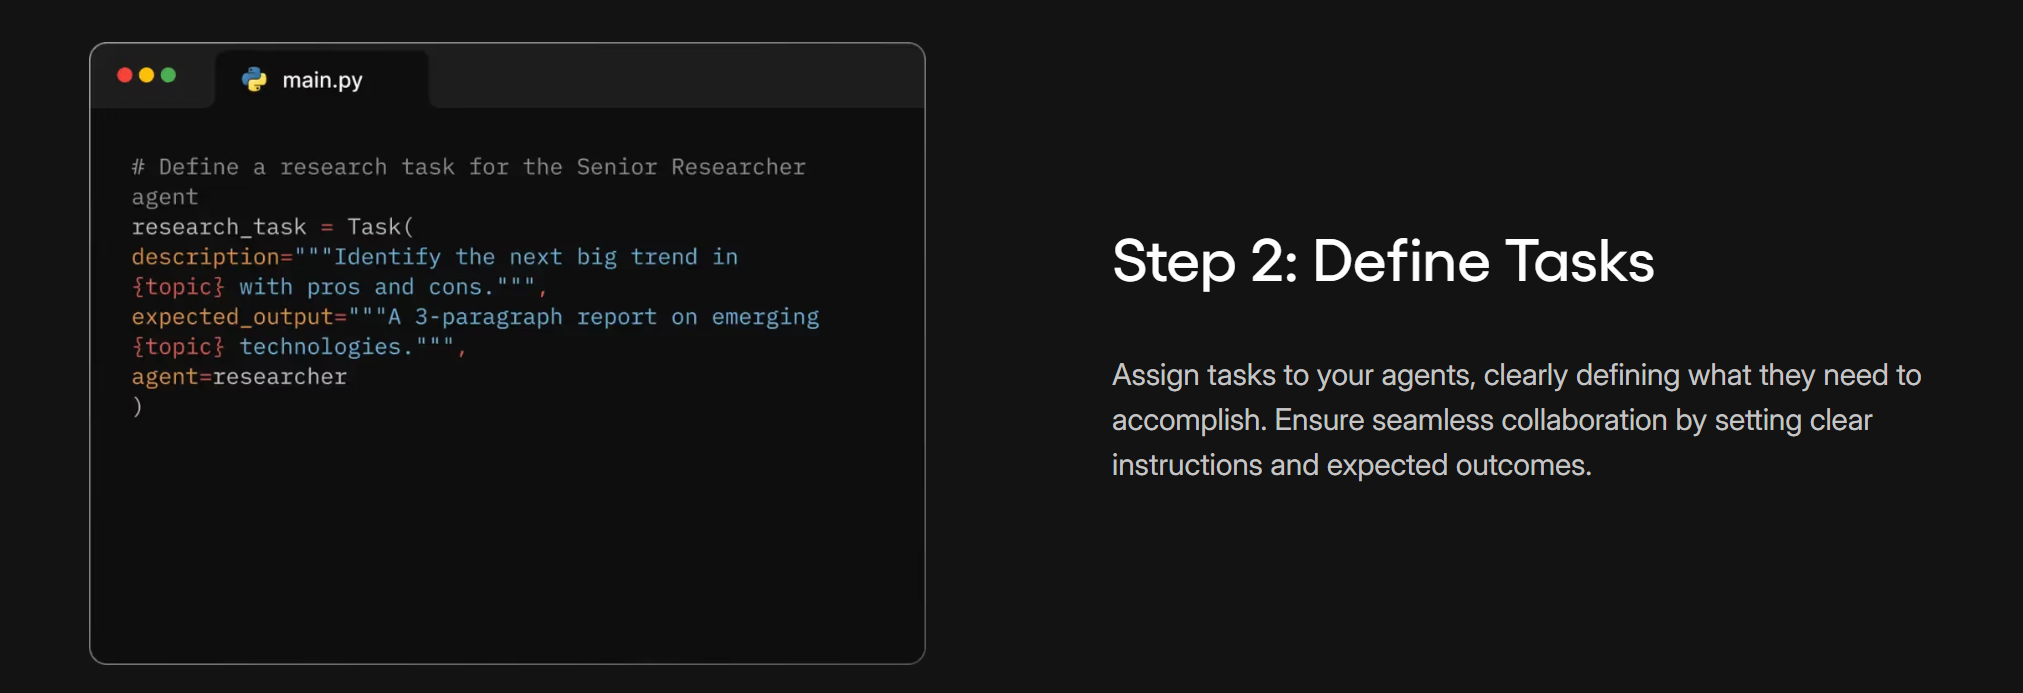

In [24]:
find_and_filter_recipes = Task(
    description = f"Find recipes that user the ingredient: {main_ingredient} and filter them to meet dietary restrictions: {dietary_restrictions}.",
    expected_output= f"One recipe using {main_ingredient} and matching {dietary_restrictions} restrictions.",
    agent = recipe_assistant,
)

guide_recipe_steps = Task(description ="Provide step-by-step instructions for the selected recipe.",
                         expected_output="Step-by-step cooking instructions for the chosen recipe.",
                          agent =recipe_assistant, )

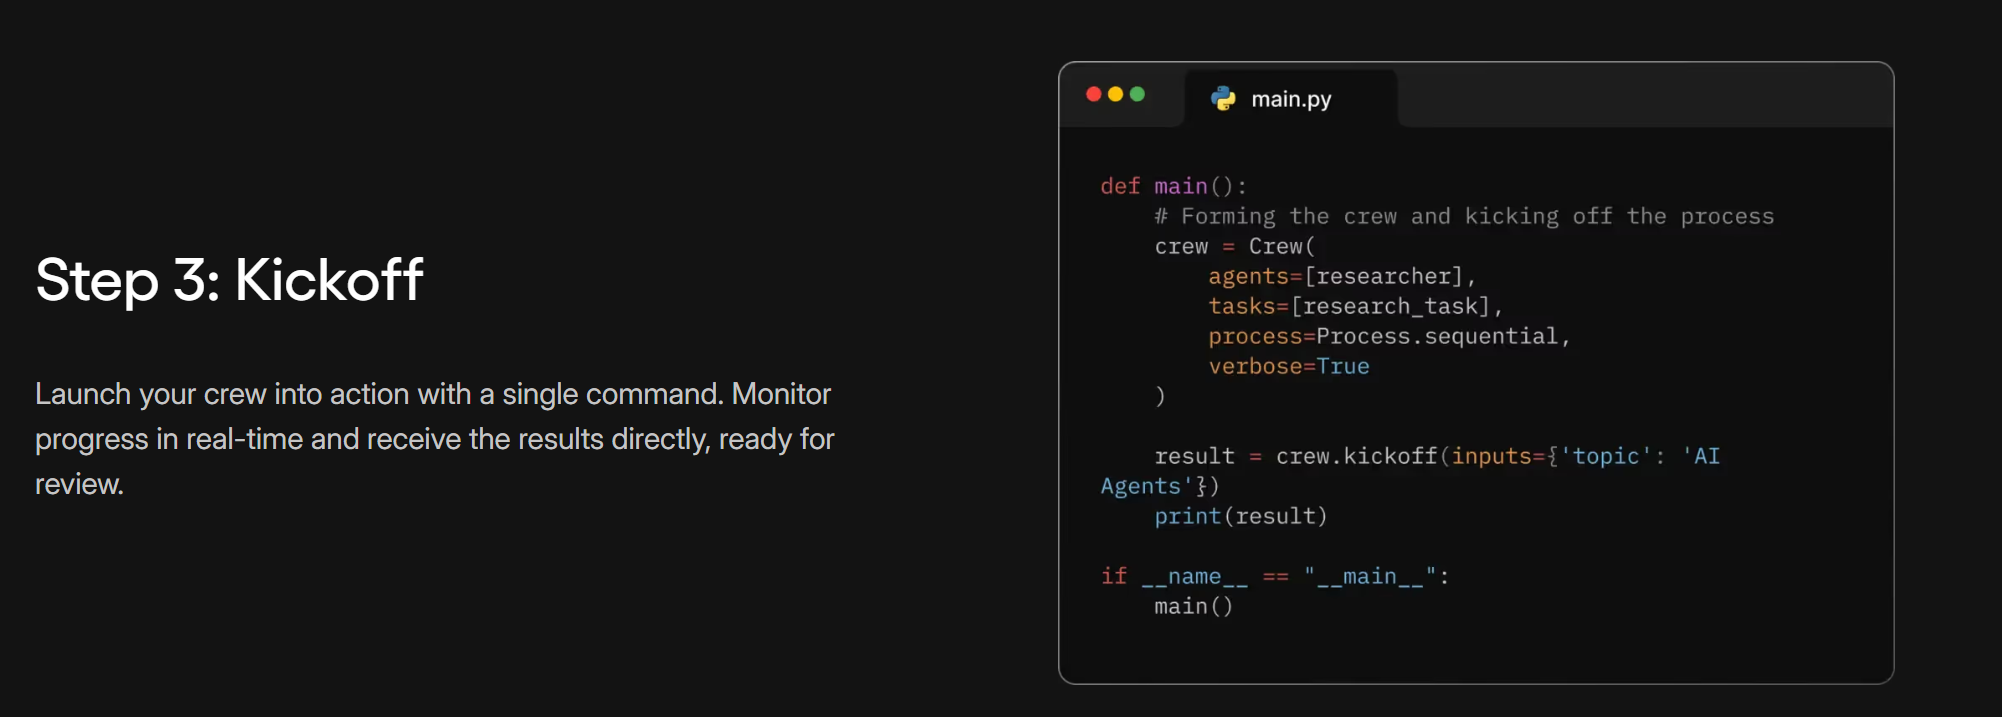

In [25]:
crew = Crew(agents=[recipe_assistant],
            tasks =[find_and_filter_recipes,guide_recipe_steps] ,
            planning=True,)

In [26]:
crew.kickoff()

# Agent: recipe assistant
## Task: Find recipes that user the ingredient: tomato and filter them to meet dietary restrictions: sugar.1. Identify Ingredients: Start the search by listing down key ingredient: Tomato. 2. Search for Recipes: Utilize a trusted recipe database to search for recipes containing tomatoes. This can include websites, cookbooks, or online cooking platforms. Example: Use search query "tomato recipes" in a digital recipe library. 3. Review Recipes: Collect a selection of recipes that contain tomatoes. Aim for at least 5 to 10 recipes for variety. 4. Filter for Dietary Restrictions: Review each recipe's ingredients to identify whether it contains added sugars or sugar-laden products (like certain sauces). Use a filtering criterion to ensure none of the recipes contain sugar-related dietary restrictions. 5. Select Recipe: After filtering, choose one recipe that meets the criteria of containing tomatoes and having no added sugars. Ensure the recipe is relatable and eas

CrewOutput(raw="**Fresh Tomato Basil Salad Recipe**\n\n**Ingredients:**\n- 4 ripe tomatoes, diced\n- 1 cup fresh basil leaves, torn\n- 1/4 cup extra virgin olive oil\n- 2 tablespoons balsamic vinegar (ensure it's sugar-free)\n- Salt and pepper to taste\n- Optional: 1/4 cup red onion, thinly sliced\n\n**Instructions:**\n\n**Step 1: Prepare the Tomatoes**  \n- Start by washing the tomatoes thoroughly under cold running water to remove any dirt or residues.  \n- Once clean, use a sharp knife to dice the tomatoes into bite-sized pieces. Aim for uniformity in size for even mixing and presentation.  \n- Place the diced tomatoes in a large mixing bowl.\n\n**Step 2: Add the Basil**  \n- Take the fresh basil leaves and rinse them gently under cold water.  \n- Pat them dry with a clean kitchen towel or paper towel.  \n- Tear the basil leaves into smaller pieces (about 1-inch size) to release their aromatic oils.  \n- Add the torn basil to the bowl with the diced tomatoes.\n\n**Step 3: Mix the Dr

# Project - Marketing Research

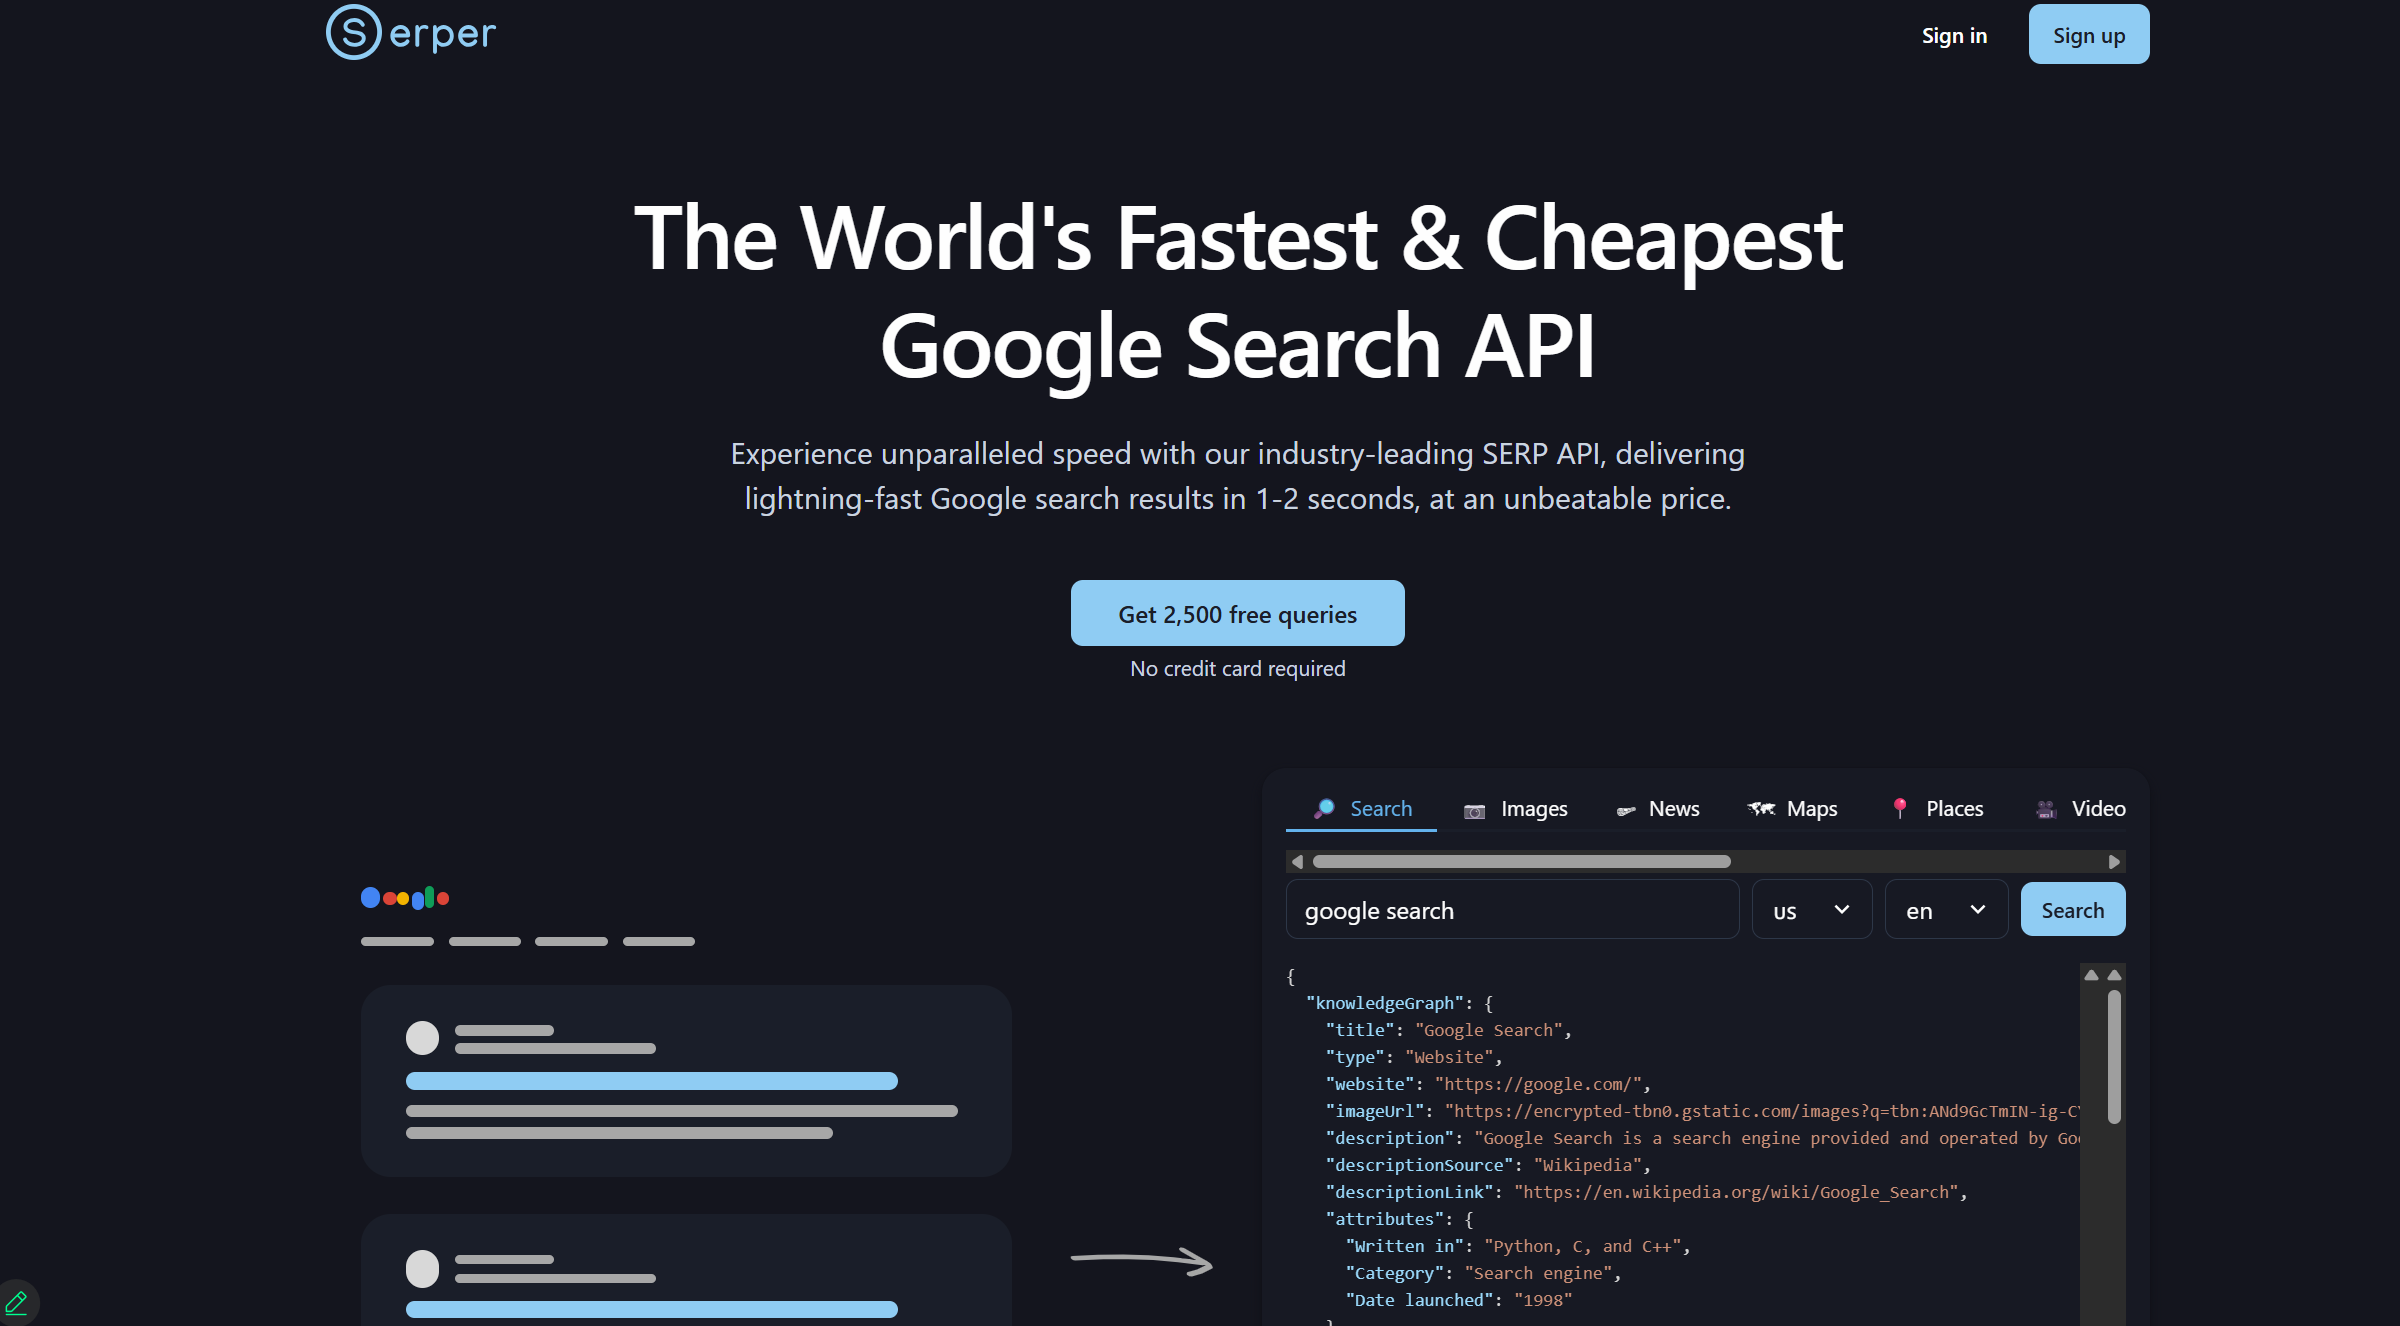

In [1]:
#!pip install --upgrade crewai
#!pip install crewai-tools

In [2]:
from crewai import Agent, Task, Crew
from crewai_tools import SerperDevTool

In [3]:
product_name="energy drink"
strategist_backstory = "and marketing strategy"

In [6]:
from getpass import getpass
SERPER_API_KEY = getpass("Enter your serper api key here :")

Enter your serper api key here :··········


In [11]:
# Part 1 - Creating Agent
market_researcher = Agent(
    role="Market Researcher",
    goal = "Analyse market trends for the product launch",
    backstory ="Experienced in marketing trends and consumer behavior analysis",
    tools = [SerperDevTool(api_key =SERPER_API_KEY )],
    verbose=True,
)


strategiest = Agent(
    role="Product Strategist",
    goal = "Create effective positioning strategies for the product",
    backstory = f"skilled in competitive positioning {strategist_backstory}",
    verbose=True,
)

In [12]:
# Part 2 - Assiging Task

gather_market_insights_task = Task(
    description = f"Browse the internet to gather insights on current market trends fo rth launch of the {product_name} product.",
    expected_output= f"List of relevant market trends and consumer preferences, relevant to {product_name}",
    agent = market_researcher,
)

develop_positioning_strategy_task = Task(
    description = f"Based on the market insights, create a positioning strategy for the {product_name} product, including analysis for the impact and target audiance",
    expected_output= f"A positioning stratey with target audience and impact notes",
    agent = strategiest,
     verbose=True,
)


In [13]:
# Part 3 - creat crewai
crew= Crew(Agents = [market_researcher, strategiest],
           tasks = [gather_market_insights_task, develop_positioning_strategy_task],
           planning= True)

In [14]:
output = crew.kickoff()

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Market Researcher                                                                                       │
│                                                                                                                 │
│  Task: Browse the internet to gather insights on current market trends fo rth launch of the energy drink        │
│  product.1. The Market Researcher will begin by setting up their workstation with necessary materials,          │
│  including market research frameworks, note-taking tools, and access to digital devices. 2. The Market          │
│  Researcher will log into the SerperDevTool, ensuring that the SERPER_API_KEY is active and confirmed. 3. They  │
│  will formulate a relevant search query that captures the essence of the market trends surrounding energy       │
│  drinks, such as 'current market trends for energy drinks 2023' or 'consumer preferences energy drinks'. 4.     │
│  Using the SerperDevTool, the Market Researcher will execute the search query, collecting at least 10 relevant  │
│  search results from the internet. 5. They will scan through the search results to identify key insights,       │
│  trends, and consumer behaviors related to energy drinks. 6. The Market Researcher will compile the gathered    │
│  insights into a structured document, categorizing them into themes such as 'flavor preferences', 'target       │
│  demographics', 'packaging trends', and 'market gaps'. 7. The final output will include a comprehensive list    │
│  of relevant market trends and consumer preferences, ready for the next task.                                   │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────── 🔧 Agent Tool Execution ────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Market Researcher                                                                                       │
│                                                                                                                 │
│  Thought: Thought: I need to start by searching the internet to gather current market trends and consumer       │
│  preferences related to energy drinks in 2023. This will help me collect relevant insights for the product      │
│  launch.                                                                                                        │
│                                                                                                                 │
│  Using Tool: Search the internet with Serper                                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────────── Tool Input ───────────────────────────────────────────────────╮
│                                                                                                                 │
│  {                                                                                                              │
│    "search_query": "current market trends for energy drinks 2023"                                               │
│  }                                                                                                              │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────────── Tool Output ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  {'searchParameters': {'q': 'current market trends for energy drinks 2023', 'type': 'search', 'num': 10,        │
│  'engine': 'google'}, 'organic': [{'title': 'Energy Drinks Market Size & Share | Industry Report, 2030',        │
│  'link': 'https://www.grandviewresearch.com/industry-analysis/energy-drinks-market', 'snippet': 'Energy drinks  │
│  market size was USD 79.39 billion in 2024 and is projected to reach USD 125.11 billion by 2030, growing at a   │
│  CAGR of 8.0% from 2025 to 2030.', 'position': 1}, {'title': 'Energy Drinks Market to Grow by USD 40.04         │
│  Billion from 2023-2027 ...', 'link':                                                                           │
│  'https://www.prnewswire.com/news-releases/energy-drinks-market-to-grow-by-usd-40-04-billion-from-2023-2027--a  │
│  s-hectic-lifestyles-drive-demand-with-ai-impact-on-market-trends---technavio-302299518.html', 'snippet': 'The  │
│  market is estimated to grow at a CAGR of 8% during the forecast period. Hectic lifestyle and need for instant  │
│  energy is driving market ...', 'position': 2}, {'title': 'Sports and energy drinks trends in the US,           │
│  exploring next', 'link': 'https://www.innovamarketinsights.com/trends/sports-and-energy-drinks-trends/',       │
│  'snippet': 'Sugar-free claims occurred in 54% of energy drinks launches, gaining 29% points and in 46% of      │
│  sports drinks launches in 2022-2023 YTD. The use of bulk and non- ...', 'position': 3}, {'title': 'US Energy   │
│  Drinks Market Analysis & Forecast 2025-2030 | Mintel', 'link':                                                 │
│  'https://store.mintel.com/report/us-energy-drinks-market-report', 'snippet': 'The US energy drink market,      │
│  estimated at $23.9 billion in 2024, is set for further growth over the next five years. Driven by flavor       │
│  innovation, increasing BFY ...', 'position': 4}, {'title': 'Energy Drinks Market Report 2025-2034 | Trends',   │
│  'link': 'https://www.thebusinessresearchcompany.com/report/energy-drinks-global-market-report', 'snippet':     │
│  'It will grow from $67.64 billion in 2024 to $72.23 billion in 2025 at a compound annual growth rate (CAGR)    │
│  of 6.8%. The growth in the historic period can be ...', 'position': 5}, {'title': ...                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────── 🔧 Agent Tool Execution ────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Market Researcher                                                                                       │
│                                                                                                                 │
│  Thought: Thought: I have gathered multiple sources containing relevant market data and insights on energy      │
│  drink trends in 2023. Next, I will analyze and extract key insights from these results focusing on flavor      │
│  preferences, target demographics, packaging trends, and market gaps.                                           │
│                                                                                                                 │
│  Using Tool: Search the internet with Serper                                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────────── Tool Input ───────────────────────────────────────────────────╮
│                                                                                                                 │
│  {                                                                                                              │
│    "search_query": "consumer preferences energy drinks 2023"                                                    │
│  }                                                                                                              │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────────── Tool Output ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  {'searchParameters': {'q': 'consumer preferences energy drinks 2023', 'type': 'search', 'num': 10, 'engine':   │
│  'google'}, 'organic': [{'title': 'Energy drinks trends in the US and Canada. As consumers seek a', 'link':     │
│  'https://www.innovamarketinsights.com/trends/energy-drinks-industry-trends/', 'snippet': 'In the US and        │
│  Canada, 23% of consumers prefer energy drinks trends with added health benefits. Taste and flavor drive        │
│  energy drink purchases ...', 'position': 1}, {'title': 'Better-for-you energy drink trends - Beverage Daily',  │
│  'link': 'https://www.beveragedaily.com/Article/2025/06/18/better-for-you-energy-drink-trends/', 'snippet':     │
│  '“The modern consumer continues leaning into wellness-minded practices, especially as it relates to food and   │
│  beverage choice, and these evolving ...', 'position': 2}, {'title': 'Healthy Energy Drinks Market Size And     │
│  Share Report 2030', 'link':                                                                                    │
│  'https://www.grandviewresearch.com/industry-analysis/healthy-energy-drinks-market-report', 'snippet': 'The     │
│  global healthy energy drinks market size was estimated at USD 4.17 billion in 2023 and is expected to reach    │
│  USD 6.37 billion by 2030, growing at a CAGR ...', 'position': 3}, {'title': "What's the Buzz? Preferences and  │
│  perceptions of policies to reduce ...", 'link':                                                                │
│  'https://www.sciencedirect.com/science/article/abs/pii/S030691922500003X', 'snippet': 'Along with evaluating   │
│  energy drink policy preferences, we explore consumer perceptions of energy drink labeling, marketing, and      │
│  access channels (e.g., retail, ...', 'position': 4}, {'title': "New study evaluates public policy preferences  │
│  for limiting children's ...", 'link':                                                                          │
│  'https://news.illinois.edu/new-study-evaluates-public-policy-preferences-for-limiting-childrens-access-to-ene  │
│  rgy-drinks/', 'snippet': 'The researchers found that respondents had the strongest preference for mandatory    │
│  and prominently displayed caffeine content labels on energy drinks.', 'position': 5}, {'title': 'North         │
│  America Energy Drinks Market | Size, share, growth | 202...                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Market Researcher                                                                                       │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  List of relevant market trends and consumer preferences for energy drinks in 2023:                             │
│                                                                                                                 │
│  1. Market Growth and Demand:                                                                                   │
│  - The global energy drinks market size was approximately USD 79.39 billion in 2024 and is projected to reach   │
│  around USD 125.11 billion by 2030, growing at a CAGR of about 8.0% from 2025 to 2030.                          │
│  - The North America market alone was valued at around USD 24.3 billion in 2023, expected to grow steadily      │
│  through 2030.                                                                                                  │
│  - Growth drivers include hectic lifestyles, demand for instant energy, and mental stimulation benefits.        │
│  - Sales have increased by over 12% recently, reflecting strong consumer interest.                              │
│                                                                                                                 │
│  2. Consumer Preferences and Behavior:                                                                          │
│  - Around 23% of consumers in the US and Canada favor energy drinks with added health benefits such as          │
│  vitamins, antioxidants, or natural ingredients.                                                                │
│  - Health-conscious consumption is rising, with a notable trend toward “better-for-you” or “healthy” energy     │
│  drinks that minimize sugar, calories, and artificial additives.                                                │
│  - Sugar-free options have surged in demand owing to health concerns including diabetes.                        │
│  - Consumers prioritize taste and flavor highly in purchase decisions.                                          │
│  - Eco-friendly, sustainable packaging is increasingly important, with 39% of US consumers preferring brands    │
│  that address environmental impact.                                                                             │
│                                                                                                                 │
│  3. Flavor Preferences:                                                                                         │
│  - Flavor innovation is a key growth factor, with popular flavors including fruit blends, tropical, citrus,     │
│  and exotic blends.                                                                                             │
│  - There is a growing consumer interest in natural, organic, and botanical flavors.                             │
│  - Use of sweeteners is shifting towards natural and low-calorie options.                                       │
│                                                                                                                 │
│  4. Target Demographics:                                                                                        │
│  - Primary consumers range from young adults (18-34 years) who seek energy boosts for active lifestyles,        │
│  students, and professionals.                                                                                   │
│  - Increasing interest among older demographics driven 

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Product Strategist                                                                                      │
│                                                                                                                 │
│  Task: Based on the market insights, create a positioning strategy for the energy drink product, including      │
│  analysis for the impact and target audiance1. The Product Strategist will review the insights document         │
│  prepared by the Market Researcher to gather a foundational understanding of current market trends and          │
│  consumer preferences. 2. They will identify key themes from the market insights that align with potential      │
│  positioning strategies, such as identifying target demographics by age, lifestyle, and preference patterns in  │
│  energy drink consumption. 3. The Product Strategist will brainstorm different positioning strategies focusing  │
│  on the unique attributes of the proposed energy drink (e.g., organic ingredients, targeted energy boosts,      │
│  flavors). 4. They will map out the potential impact of each strategy on the target audience, considering       │
│  factors such as brand appeal, relevance, and consumer engagement. 5. The Product Strategist will categorize    │
│  the strategies by their potential effectiveness and alignment with the market trends identified by the Market  │
│  Researcher. 6. Utilizing visual aids, such as charts or slides, they will draft a positioning strategy         │
│  document that includes an analysis of the target audience, proposed strategies, expected impacts, and          │
│  potential market opportunities. 7. The final output will be a clear and concise positioning strategy           │
│  document, ready for team review, that outlines the target audience and notes on how the product will impact    │
│  the market landscape.                                                                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Product Strategist                                                                                      │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  Positioning Strategy Document for New Energy Drink Product                                                     │
│                                                                                                                 │
│  I. Target Audience Analysis                                                                                    │
│                                                                                                                 │
│  Primary Target Audience:                                                                                       │
│  - Young adults aged 18-34, encompassing active individuals, students, and young professionals.                 │
│  - Motivated by need for instant energy boosts to support hectic lifestyles and mental focus.                   │
│  - Health-conscious subgroup within this cohort prioritizing low sugar/calorie intake, natural ingredients,     │
│  and added health benefits.                                                                                     │
│  - Both males and expanding female consumer segments, with females gravitating more towards healthier options.  │
│  - Environmentally aware consumers who value sustainability in product packaging.                               │
│                                                                                                                 │
│  Secondary Target Audience:                                                                                     │
│  - Older adults above 35 showing rising interest due to wellness trends.                                        │
│  - Consumers specifically seeking functional benefits such as cognitive enhancement, relaxation, or hydration   │
│  tailored to lifestyle needs.                                                                                   │
│                                                                                                                 │
│  II. Key Positioning Themes and Market Insights Alignment                                                       │
│                                                                                                                 │
│  1. Healthy and Functional Energy Boost:                                                                        │
│  - Position the product as a “better-for-you” energy drink utilizing organic ingredients, natural sweeteners,   │
│  and added functional benefits like adaptogens, nootropics, vitamins, or antioxidants.                          │
│  - Emphasize sugar-free or low-calorie formulation addressing the growing consumer health concerns (e.g.,       │
│  diabetes risk).                                                                                                │
│  - Transparency in labeling, clearly communicating caffeine content and health claims.                          │
│                                                                                                                 │
│  2. Flavor Innovation with Natural and Botanical Profiles:                                                      │
│  - Highlight unique, natural fruit blends and exotic botanical flavors aligning with consumer preferences for   │
│  taste and authenticity.                                                                                        │
│  - Use natural sweeteners to enhance flavor appeal and 



╭────────────────────────────── Execution Traces ──────────────────────────────╮
│                                                                              │
│  🔍 Detailed execution traces are available!                                 │
│                                                                              │
│  View insights including:                                                    │
│    • Agent decision-making process                                           │
│    • Task execution flow and timing                                          │
│    • Tool usage details                                                      │
│                                                                              │
╰──────────────────────────────────────────────────────────────────────────────╯
Would you like to view your execution traces? [y/N] (20s timeout): 